# 07 · EDA — CICIoT2023 (`IoT23`)
**Owner:** Yassine Mtibaa · **Phase 4 — Exploratory data analysis** · Cross-Network Intrusion Analysis (CRISP-DM)

My section of the team EDA (kept in its own notebook to avoid git conflicts in `07_eda.ipynb`). Tasks from `docs/TASK_BOARD.md`:

| Task | Section |
|---|---|
| 4.7 CICIoT2023 EDA: descriptive statistics, distributions, correlations, relationships with the target | §1–§3 |
| 4.5 Normality check — justifies the non-parametric tests used by the whole team | §4 |
| 4.5 Chi-square test: protocol × attack family (SQ1) | §5 |
| 4.4 Interesting patterns and trends per family | §6 |
| 4.7 Comparison with the NetFlow datasets at family level (SQ2) | §7 |

**Data:** `data/processed/IoT23_clean.parquet`, written by notebook 05 (cleaned, deduplicated, at most 200,000 rows per attack label).
Because of that cap, **shares of rows in this sample reflect the sampling design, not the real traffic mix** — the real mix is in notebook 05 (2.6).
Statistics *within* a label or family are not affected by the cap.

In [1]:
import sys; sys.path.append("..")
from src.config import *

import warnings; warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.feature_selection import mutual_info_classif
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 60)

SOURCE = "IoT23"
df = pd.read_parquet(PROCESSED_DIR / f"{SOURCE}_clean.parquet")
df["attack_family"] = df["attack_family"].astype(str)
df["attack_label"] = df["attack_label"].astype(str)
df["Protocol_Type"] = df["Protocol_Type"].astype(int)

LABEL_COLS = ["Label", "source_dataset", "attack_label", "attack_family", "is_attack", "conflicting_features"]
FEATURES = [c for c in df.columns if c not in LABEL_COLS]                        # 39 window features
NUMERIC = [c for c in FEATURES if c != "Protocol_Type"]                           # Protocol_Type is a code
FAMILY_ORDER = [f for f in [BENIGN, "Denial of service", "Malware and botnets", "Reconnaissance",
                            "Interception and spoofing", "Web and injection", "Credential attacks"] if f in set(df["attack_family"])]
PAL = dict(zip(FAMILY_ORDER, sns.color_palette("tab10", len(FAMILY_ORDER))))
PROTO_NAMES = {0: "Other (non-IP)", 1: "ICMP", 2: "IGMP", 6: "TCP", 17: "UDP", 47: "GRE"}
KEY = ["Rate", "IAT", "AVG", "Std", "Max", "Min", "Header_Length", "Time_To_Live", "Tot_sum", "Number"]
RNG = np.random.default_rng(RANDOM_STATE)

def per_group(d, col, n):
    "Random sample of at most n rows from each group (keeps the group column)."
    return pd.concat([g.sample(min(len(g), n), random_state=RANDOM_STATE) for _, g in d.groupby(col, observed=True)], ignore_index=True)

def savefig(name):
    plt.savefig(FIG_DIR / f"IoT23_eda_{name}.png", dpi=150, bbox_inches="tight"); plt.show()

print(f"{len(df):,} rows | {len(FEATURES)} features | {df['attack_label'].nunique()} labels | {len(FAMILY_ORDER)} families (incl. Benign)")
df.groupby("attack_family").agg(labels=("attack_label", "nunique"), rows=("attack_label", "size")).loc[FAMILY_ORDER]

4,420,714 rows | 39 features | 34 labels | 7 families (incl. Benign)


,labels,rows
attack_family,,
Benign,1,200000
Denial of service,16,2718437
Malware and botnets,3,600000
Reconnaissance,5,499130
Interception and spoofing,2,366920
Web and injection,6,23707
Credential attacks,1,12520


---
## 1 · Descriptive statistics
### 1.1 The four families of statistics for the key variables
Central tendency (mean, median), dispersion (std, IQR, coefficient of variation), shape (skewness, excess kurtosis) and position (quartiles, P99).

In [2]:
def describe(x):
    x = x.astype("float64")
    q1, q3 = x.quantile([.25, .75])
    return pd.Series({"mean": x.mean(), "median": x.median(), "std": x.std(), "IQR": q3 - q1,
                      "CV %": 100 * x.std() / x.mean() if x.mean() else np.nan,
                      "skewness": x.skew(), "excess kurtosis": x.kurt(),
                      "min": x.min(), "Q1": q1, "Q3": q3, "P99": x.quantile(.99), "max": x.max()})
desc = df[KEY].apply(describe).T
desc.to_csv(TABLE_DIR / "IoT23_eda_describe.csv")
desc.round(3)

,mean,median,std,IQR,CV %,skewness,excess kurtosis,min,Q1,Q3,P99,max
Rate,14218.637,5258.458,36336.764,16850.917,255.557,35.842,4760.504,0.0,1032.191,17883.107,108212.180,1.048576e+07
IAT,0.027,0.000,23.389,0.001,85481.406,1820.947,3590848.348,0.0,0.000,0.001,0.043,4.666521e+04
AVG,342.327,89.200,401.300,518.000,117.227,1.792,5.345,46.0,60.000,578.000,1613.600,8.754000e+03
Std,186.866,17.000,323.820,249.667,173.290,3.147,22.935,0.0,0.000,249.667,1296.861,9.730180e+03
Max,670.626,230.000,972.715,1206.000,145.046,4.339,41.893,46.0,60.000,1266.000,4410.000,3.771400e+04
Min,116.726,60.000,190.426,6.000,163.139,4.928,31.701,42.0,60.000,66.000,1203.000,7.306000e+03
Header_Length,14.998,19.800,10.209,12.200,68.069,0.155,-0.535,0.0,7.920,20.120,36.800,6.000000e+01
Time_To_Live,74.071,64.000,28.113,3.180,37.955,3.549,14.155,0.0,64.000,67.180,215.100,2.550000e+02
Tot_sum,24689.644,6032.000,31797.790,48916.000,128.790,1.250,0.082,120.0,6000.000,54916.000,94400.000,3.150240e+05
Number,77.409,100.000,38.977,77.000,50.352,-1.149,-0.678,2.0,23.000,100.000,100.000,1.000000e+02


**Interpretation.** Every traffic variable is strongly **right-skewed**: `Rate` has a mean of 14,219 pkt/s but a median of 5,258 (skewness 35.8, excess kurtosis 4,760), and `IAT` is even more extreme (skewness 1,821) — a handful of windows with very long gaps dominate its mean and standard deviation. The coefficient of variation is above 100 % for almost every size and rate variable. The mean and standard deviation are therefore poor summaries: **medians, IQRs and log scales** are used from here on. `Header_Length` is the only near-symmetric variable (skewness 0.16). `Number` takes essentially two values (median 100, Q1 23): see §6.3.

### 1.2 Typical value per family (median and IQR)

In [3]:
med = df.groupby("attack_family")[KEY].median().loc[FAMILY_ORDER]
iqr = (df.groupby("attack_family")[KEY].quantile(.75) - df.groupby("attack_family")[KEY].quantile(.25)).loc[FAMILY_ORDER]
fam_tab = pd.concat({"median": med, "IQR": iqr}, axis=1).swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False)
fam_tab = fam_tab[[c for k in KEY for c in fam_tab.columns if c[0] == k]]
fam_tab.to_csv(TABLE_DIR / "IoT23_eda_family_medians.csv")
fam_tab.round(3)

Rate               IAT                AVG                 Std              Max             Min        Header_Length        Time_To_Live         Tot_sum           \
                                 median        IQR median    IQR      median     IQR      median      IQR  median      IQR median    IQR        median    IQR       median    IQR   median      IQR   
attack_family                                                                                                                                                                                         
Benign                       170.598007    503.734  0.007  0.011  249.800003  956.10  409.472992  844.715  1474.0  2732.00   66.0    6.0     29.600000   8.00    98.699997  73.50   2497.0   9561.0   
Denial of service          12291.000977  23619.286  0.000  0.000   60.290001  122.00    1.969000  290.195    78.0  1454.00   60.0    0.0     19.799999  12.08    64.000000   1.27   6029.0  12141.0   
Malware and botnets         4402.589844   4498.520  0.000  0.000  572.799988   28.46   48.000000   71.478   578.0    38.00  105.0  518.0      0.240000   8.00    64.000000   1.06  57280.0   2818.0   
Reconnaissance               122.012001    482.620  0.009  0.016  106.599998   90.40   67.763000  116.735   230.0   318.00   60.0    6.0     22.799999   8.00    86.800003  50.70   1066.0    904.0   
Interception and spoofing    482.369995   2208.525  0.002  0.008  359.299988  794.10  328.877014  554.095  1203.0  1253.00   66.0   16.0     24.000000  20.00    82.400002  55.90   3591.0   7937.0   
Web and injection             72.509003    192.386  0.016  0.027  144.199997  197.35   86.543999  171.643   347.0  1264.00   60.0    6.0     22.400000  13.60    92.599998  52.90   1442.0   1972.5   
Credential attacks           106.630997    196.651  0.010  0.017  120.500000  132.35   70.833000  282.052   230.0   856.75   60.0    6.0     24.799999  11.60    83.099998  48.50   1205.0   1323.5   

                          Number       
                          median  IQR  
attack_family                          
Benign                      10.0  0.0  
Denial of service          100.0  0.0  
Malware and botnets        100.0  0.0  
Reconnaissance              10.0  0.0  
Interception and spoofing   10.0  0.0  
Web and injection           10.0  0.0  
Credential attacks          10.0  0.0

In [4]:
bva = df.groupby("is_attack")[KEY].median().T.rename(columns={0: "Benign (median)", 1: "Attack (median)"})
bva["attack / benign"] = (bva["Attack (median)"] / bva["Benign (median)"].replace(0, np.nan)).round(2)
bva

is_attack,Benign (median),Attack (median),attack / benign
Rate,170.597595,5851.673340,34.30
IAT,0.006654,0.000175,0.03
AVG,249.800003,79.500000,0.32
Std,409.472717,13.500000,0.03
Max,1474.000000,230.000000,0.16
Min,66.000000,60.000000,0.91
Header_Length,29.600000,19.600000,0.66
Time_To_Live,98.699997,64.000000,0.65
Tot_sum,2497.000000,6037.000000,2.42
Number,10.000000,100.000000,10.00


**Interpretation.**
* **Denial of service** windows are made of **minimum-size packets** (median `AVG` 60 B, `Std` ≈ 2 B) sent at a **very high rate** (median 12,291 pkt/s, ≈ 72× benign) with almost no gap between packets (`IAT` ≈ 0).
* **Mirai** (Malware and botnets) is also high-rate (4,403 pkt/s) but with **large, uniform packets** (median `AVG` 573 B, IQR 28 B) and `Header_Length` ≈ 0 — GRE-encapsulated floods carry no TCP/UDP header.
* **Benign** traffic has large and **highly variable** packets (median `AVG` 250 B, `Std` 409 B, `Max` 1,474 B) at a low rate (171 pkt/s).
* **Reconnaissance, web, credential and spoofing** attacks are **low-rate** (73–482 pkt/s) with mid-size packets: in rate and size they sit close to benign traffic, which makes them the hardest families to separate.
* `Time_To_Live`: benign windows have a median TTL of 98.7 (a mix of Linux 64 and Windows 128 hosts) while every attack family is at ≈ 64 — the attack machines all ran the same OS. TTL partly identifies *the lab machines*, not the attack behaviour (same warning as in the UNSW-NB15 analysis).
* Benign vs attack overall: attacks have a 34× higher rate, 3× smaller packets and a 30× smaller packet-size spread.

### 1.3 Distributions of the key variables by family (log scale)

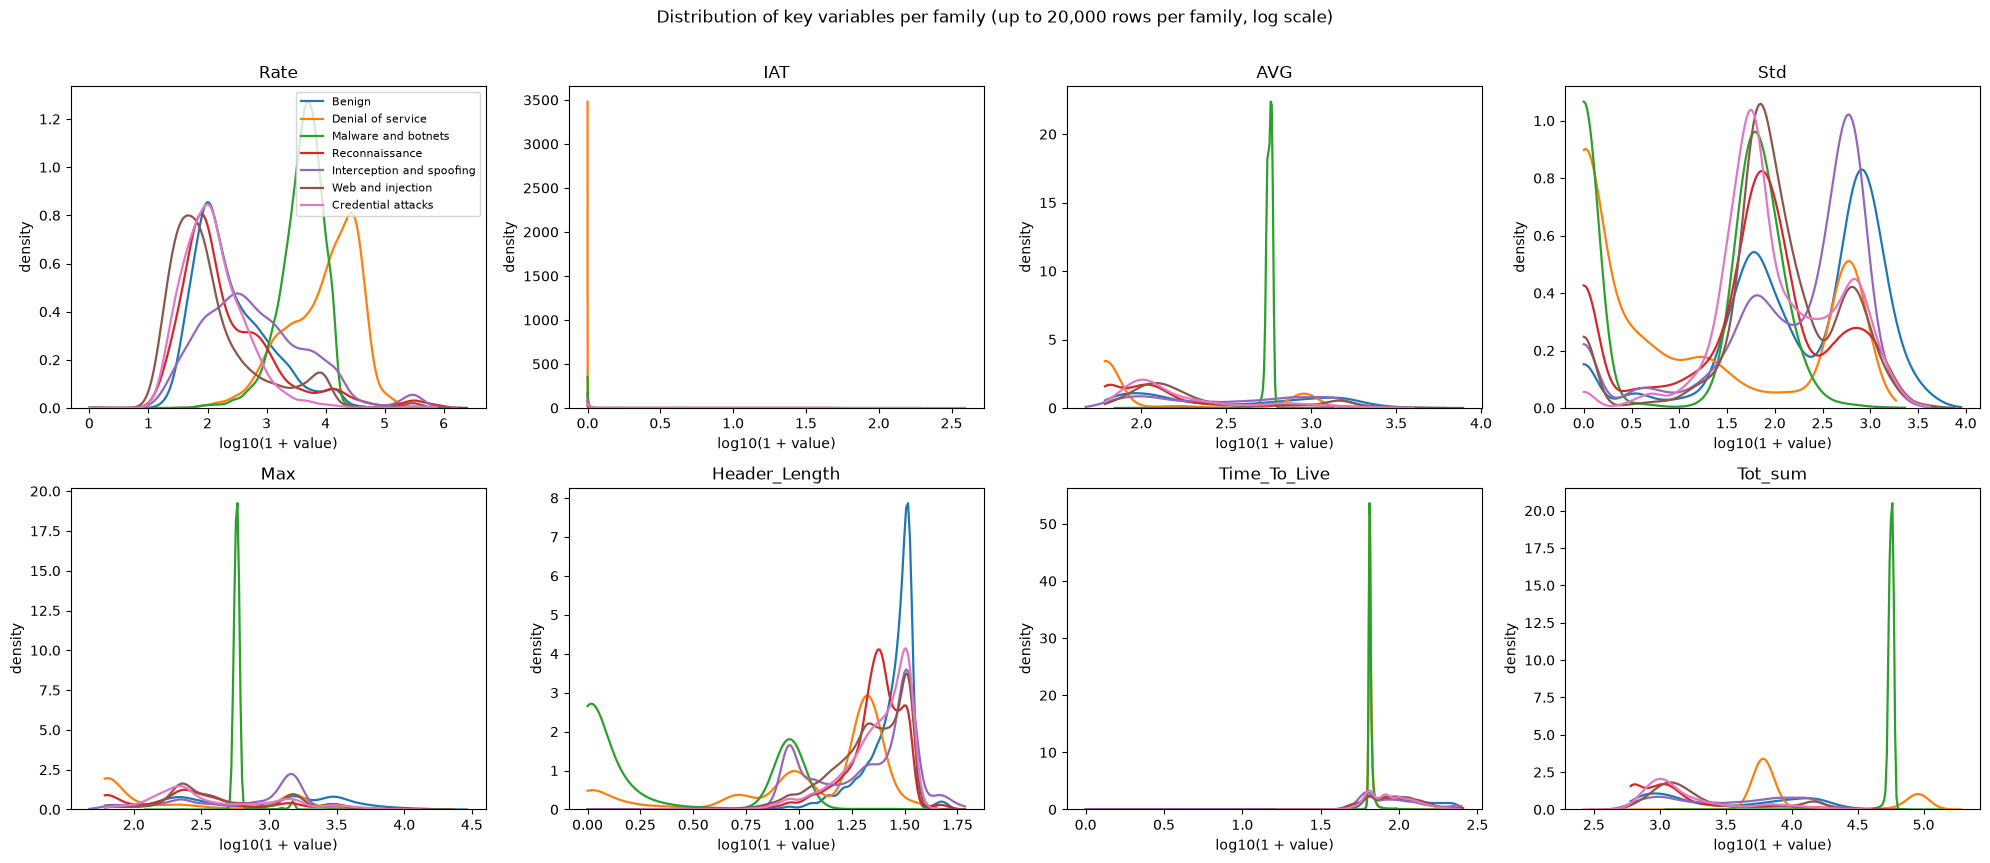

In [5]:
S = per_group(df, "attack_family", 20_000)
fig, axes = plt.subplots(2, 4, figsize=(20, 8.5)); axes = axes.ravel()
for ax, c in zip(axes, ["Rate", "IAT", "AVG", "Std", "Max", "Header_Length", "Time_To_Live", "Tot_sum"]):
    for f in FAMILY_ORDER:
        v = np.log10(S.loc[S.attack_family == f, c].astype(float) + 1)
        sns.kdeplot(v, ax=ax, label=f, color=PAL[f], lw=1.6, bw_adjust=1.2, warn_singular=False, cut=0)
    ax.set_title(c); ax.set_xlabel("log10(1 + value)"); ax.set_ylabel("density")
axes[0].legend(fontsize=8)
plt.suptitle("Distribution of key variables per family (up to 20,000 rows per family, log scale)", y=1.01)
plt.tight_layout(); savefig("distributions_by_family")

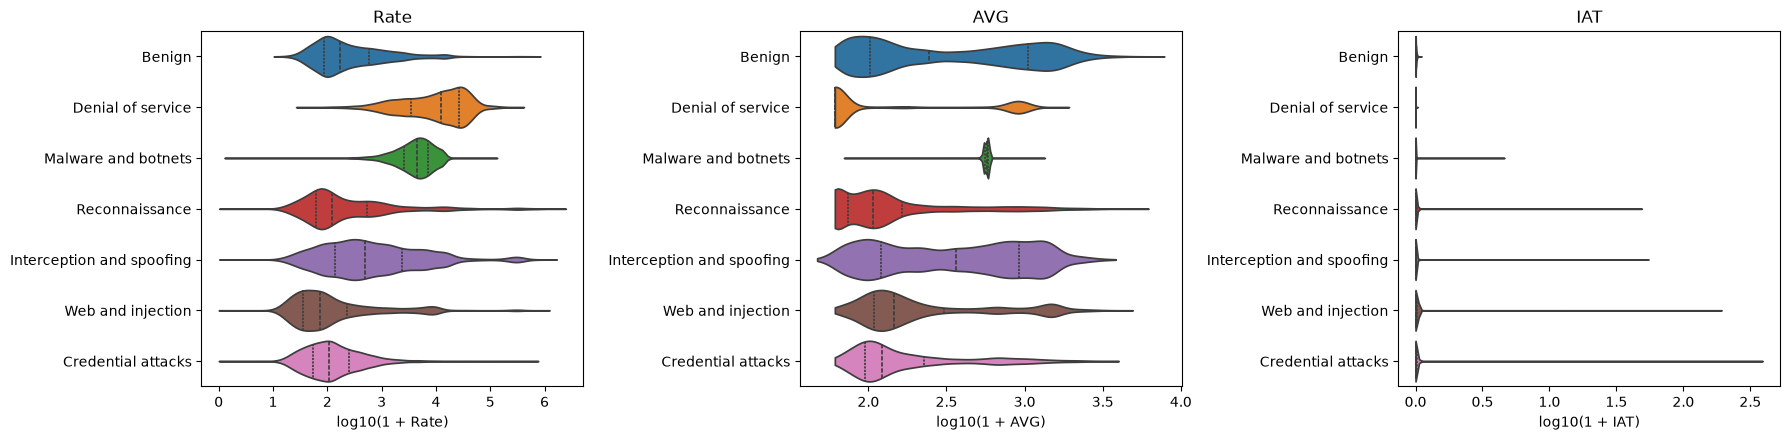

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, c in zip(axes, ["Rate", "AVG", "IAT"]):
    sns.violinplot(data=S, x=np.log10(S[c].astype(float) + 1), y="attack_family", order=FAMILY_ORDER, palette=PAL,
                   cut=0, inner="quartile", ax=ax, density_norm="width")
    ax.set_xlabel(f"log10(1 + {c})"); ax.set_ylabel(""); ax.set_title(c)
plt.tight_layout(); savefig("violins_rate_avg_iat")

**Interpretation.** On a log scale the families occupy different regions: DoS is concentrated at the far right of `Rate` and the far left of `AVG`/`Std`; Mirai forms a narrow peak around 570 B; benign traffic is the broadest distribution on every size variable. Many curves are **multimodal** (e.g. `Header_Length` with peaks at 0, ≈ 8 and ≈ 20 B, matching ICMP/GRE, UDP and TCP headers) — a first sign that no single normal curve can describe these variables (§4). The violins show that the low-rate families (reconnaissance, web, credential) overlap heavily with benign traffic.

---
## 2 · Correlation analysis
Spearman's ρ (rank correlation) is used rather than Pearson's r because the features are heavily skewed and contain extreme values (§1.1):
Spearman measures any *monotonic* relationship and is not dominated by outliers. Computed on 300,000 random rows.

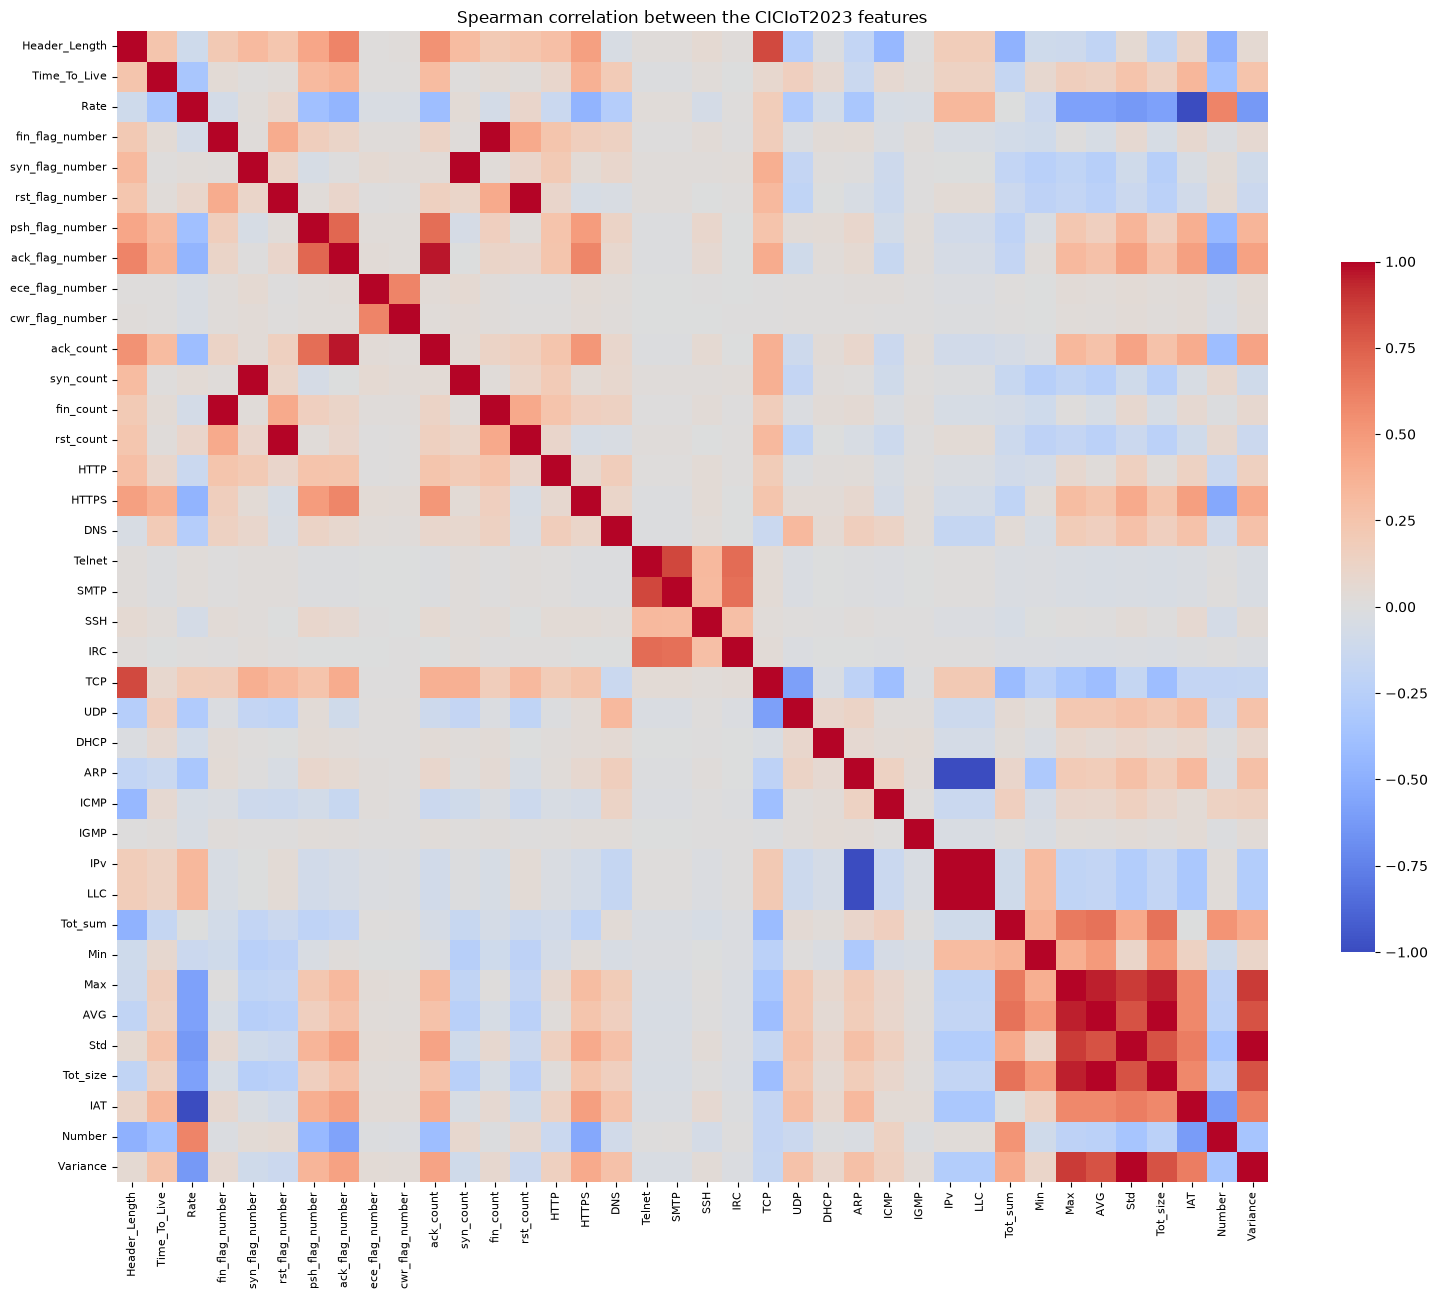

constant in this sample (excluded): []


In [7]:
C = df[NUMERIC].sample(min(len(df), 300_000), random_state=RANDOM_STATE).astype("float64")
const = [c for c in NUMERIC if C[c].nunique() <= 1]
rho = C.drop(columns=const).corr(method="spearman")
pear = C.drop(columns=const).corr(method="pearson")
fig, ax = plt.subplots(figsize=(16, 13))
sns.heatmap(rho, cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True, ax=ax, cbar_kws={"shrink": .6},
            xticklabels=True, yticklabels=True)
ax.set_title("Spearman correlation between the CICIoT2023 features"); ax.tick_params(labelsize=8)
plt.tight_layout(); savefig("correlation_heatmap")
print("constant in this sample (excluded):", const)

In [8]:
up = rho.where(np.triu(np.ones(rho.shape, dtype=bool), k=1)).stack()
pairs = up[up.abs() >= 0.9].sort_values(key=abs, ascending=False).rename("Spearman ρ").to_frame()
pairs["Pearson r"] = [pear.loc[a, b] for a, b in pairs.index]
pairs.to_csv(TABLE_DIR / "IoT23_eda_strong_correlations.csv")
print(f"{len(pairs)} pairs with |ρ| >= 0.9")
pairs.round(3)

12 pairs with |ρ| >= 0.9


Spearman ρ  Pearson r
AVG             Tot_size        1.000      1.000
IPv             LLC             1.000      1.000
ARP             LLC            -1.000     -1.000
                IPv            -1.000     -1.000
Std             Variance        1.000      0.735
rst_flag_number rst_count       0.999      0.946
fin_flag_number fin_count       0.999      0.991
syn_flag_number syn_count       0.997      0.963
Rate            IAT            -0.995     -0.002
ack_flag_number ack_count       0.967      0.617
Max             Tot_size        0.950      0.745
                AVG             0.950      0.745

**Interpretation.** 12 pairs have |ρ| ≥ 0.9. They confirm the redundancies found in phase 2 and add two:
* exact copies or formulas: `AVG` = `Tot_size`, `IPv` = `LLC`, `Variance` = `Std`², each `*_count` ≈ its `*_flag_number` (× `Number`);
* **`ARP` = 1 − `IPv`** (ρ = −1): a packet is either IP or ARP, so the three columns carry one piece of information;
* **`Rate` ↔ `IAT` (ρ = −0.995)**: the rate is essentially 1 / inter-arrival time.

The Pearson coefficients are much lower for some of these pairs (`Rate`–`IAT`: r = −0.002, `Std`–`Variance`: 0.74): Pearson only measures *linear* relations and is dominated by extreme values, which is exactly why Spearman was chosen. For phase 5, keeping one feature of each group avoids feeding the same information several times.

---
## 3 · Relationships between the features and the target
### 3.1 Each feature against `is_attack`
Spearman's ρ with the binary target (equivalent to a rank-biserial association) and the median per class, on all rows of the sample.

In [9]:
y = df["is_attack"].astype("float64")
rel = pd.DataFrame({"ρ with is_attack": [stats.spearmanr(C[c], df.loc[C.index, "is_attack"])[0] if c in C and C[c].nunique() > 1 else np.nan for c in NUMERIC],
                    "benign median": df.loc[df.is_attack == 0, NUMERIC].median().values,
                    "attack median": df.loc[df.is_attack == 1, NUMERIC].median().values}, index=NUMERIC)
rel = rel.reindex(rel["ρ with is_attack"].abs().sort_values(ascending=False).index)
rel.to_csv(TABLE_DIR / "IoT23_eda_feature_vs_is_attack.csv")
rel.head(15).round(3)

,ρ with is_attack,benign median,attack median
Number,0.377,10.000,100.000
HTTPS,-0.327,0.800,0.000
ack_flag_number,-0.285,0.900,0.010
Header_Length,-0.257,29.600,19.600
IAT,-0.257,0.007,0.000
Rate,0.252,170.598,5851.673
ack_count,-0.209,9.000,1.000
Time_To_Live,-0.209,98.700,64.000
Variance,-0.196,167667.891,182.250
Std,-0.196,409.473,13.500


### 3.2 Profile of each family (median of every feature, scaled 0–1 across families)

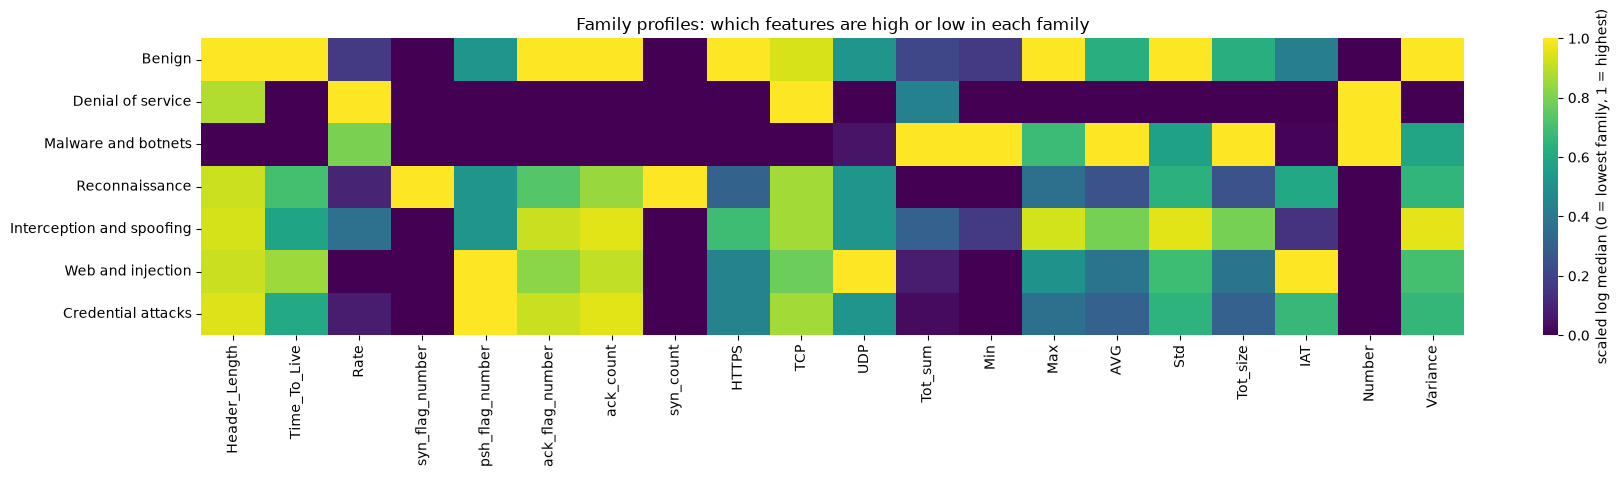

In [10]:
prof = df.groupby("attack_family")[NUMERIC].median().loc[FAMILY_ORDER]
prof = np.log1p(prof.clip(lower=0))
prof = (prof - prof.min()) / (prof.max() - prof.min()).replace(0, np.nan)
prof = prof.dropna(axis=1, how="all")
fig, ax = plt.subplots(figsize=(18, 4.8))
sns.heatmap(prof, cmap="viridis", ax=ax, cbar_kws={"label": "scaled log median (0 = lowest family, 1 = highest)"})
ax.set_title("Family profiles: which features are high or low in each family"); ax.set_ylabel("")
plt.tight_layout(); savefig("family_profiles")

**Interpretation.** The single strongest association with `is_attack` is **`Number`** (ρ = 0.38): attack windows hold 100 packets, benign windows 10 — a property of how the dataset was built, not of the attacks (§6.3). Among real traffic features, the strongest are **less HTTPS** (ρ = −0.33), **fewer ACK flags** (−0.29), shorter headers and gaps, a **higher rate** (+0.25) and a smaller packet-size spread. Every |ρ| stays below 0.4: no single feature separates benign from attack traffic on its own, which supports a multi-feature model (SQ3). The family profiles make the contrasts visible: DoS is high on rate and flags, Mirai high on packet size and GRE, benign high on size variability and HTTPS.

---
## 4 · Normality check (task 4.5)
**Why:** parametric tests (t-test, ANOVA) assume normally distributed data within each group. If the features are not normal, the team uses the
non-parametric equivalents — **Mann–Whitney U** (2 groups), **Kruskal–Wallis + Dunn** (several groups) and **Kolmogorov–Smirnov** (distributions).

**How (three complementary checks, as in the course):**
1. **Shape statistics** — skewness and excess kurtosis (0 for a normal distribution).
2. **Visual** — histogram against the fitted normal curve, and Q–Q plot.
3. **Formal tests** — Shapiro–Wilk (H₀: the data come from a normal distribution) on random subsamples of 5,000 rows (its limit), and D'Agostino–Pearson K² on 100,000 rows.
   With hundreds of thousands of rows any tiny deviation is "significant", so the formal tests are read together with the shape statistics and plots.

Each check is done on the raw values and after a log transform (`log1p`), overall and inside each family.

In [11]:
NORM = ["Rate", "IAT", "AVG", "Std", "Max", "Header_Length", "Time_To_Live", "Tot_sum"]
def norm_row(x):
    x = x.astype("float64").dropna()
    if x.nunique() < 3: return pd.Series({"n": len(x), "skewness": np.nan, "excess kurtosis": np.nan, "Shapiro W": np.nan, "Shapiro p": np.nan, "D'Agostino p": np.nan})
    xs = x.sample(min(len(x), 5000), random_state=RANDOM_STATE)
    xd = x.sample(min(len(x), 100_000), random_state=RANDOM_STATE)
    sw = stats.shapiro(xs)
    return pd.Series({"n": len(x), "skewness": x.skew(), "excess kurtosis": x.kurt(), "Shapiro W": sw.statistic,
                      "Shapiro p": sw.pvalue, "D'Agostino p": stats.normaltest(xd).pvalue if len(xd) >= 20 else np.nan})
norm_raw = pd.DataFrame({c: norm_row(df[c]) for c in NORM}).T
norm_log = pd.DataFrame({c: norm_row(np.log1p(df[c].astype("float64"))) for c in NORM}).T
norm = pd.concat({"raw": norm_raw, "log1p": norm_log}, axis=1)
norm.to_csv(TABLE_DIR / "IoT23_eda_normality_overall.csv")
norm.round(4)

raw                                                                  log1p                                                           
                       n   skewness excess kurtosis Shapiro W Shapiro p D'Agostino p          n  skewness excess kurtosis Shapiro W Shapiro p D'Agostino p
Rate           4420714.0    35.8417    4.760504e+03    0.3709       0.0          0.0  4420714.0   -0.6288         -0.3633    0.9557       0.0          0.0
IAT            4420714.0  1820.9467    3.590848e+06    0.0133       0.0          0.0  4420714.0  137.8984      25337.5406    0.0531       0.0          0.0
AVG            4420714.0     1.7922    5.344800e+00    0.7337       0.0          0.0  4420714.0    0.5061         -1.4538    0.7895       0.0          0.0
Std            4420714.0     3.1470    2.293470e+01    0.6084       0.0          0.0  4420714.0    0.1841         -1.5476    0.8540       0.0          0.0
Max            4420714.0     4.3391    4.189340e+01    0.6003       0.0          0.0  4420714.0    0.2679         -1.3302    0.8819       0.0          0.0
Header_Length  4420714.0     0.1550   -5.351000e-01    0.9281       0.0          0.0  4420714.0   -1.1541          0.0077    0.8098       0.0          0.0
Time_To_Live   4420714.0     3.5493    1.415520e+01    0.5003       0.0          0.0  4420714.0    1.7384         14.1360    0.6059       0.0          0.0
Tot_sum        4420714.0     1.2503    8.170000e-02    0.7072       0.0          0.0  4420714.0    0.1015         -0.8004    0.8896       0.0          0.0

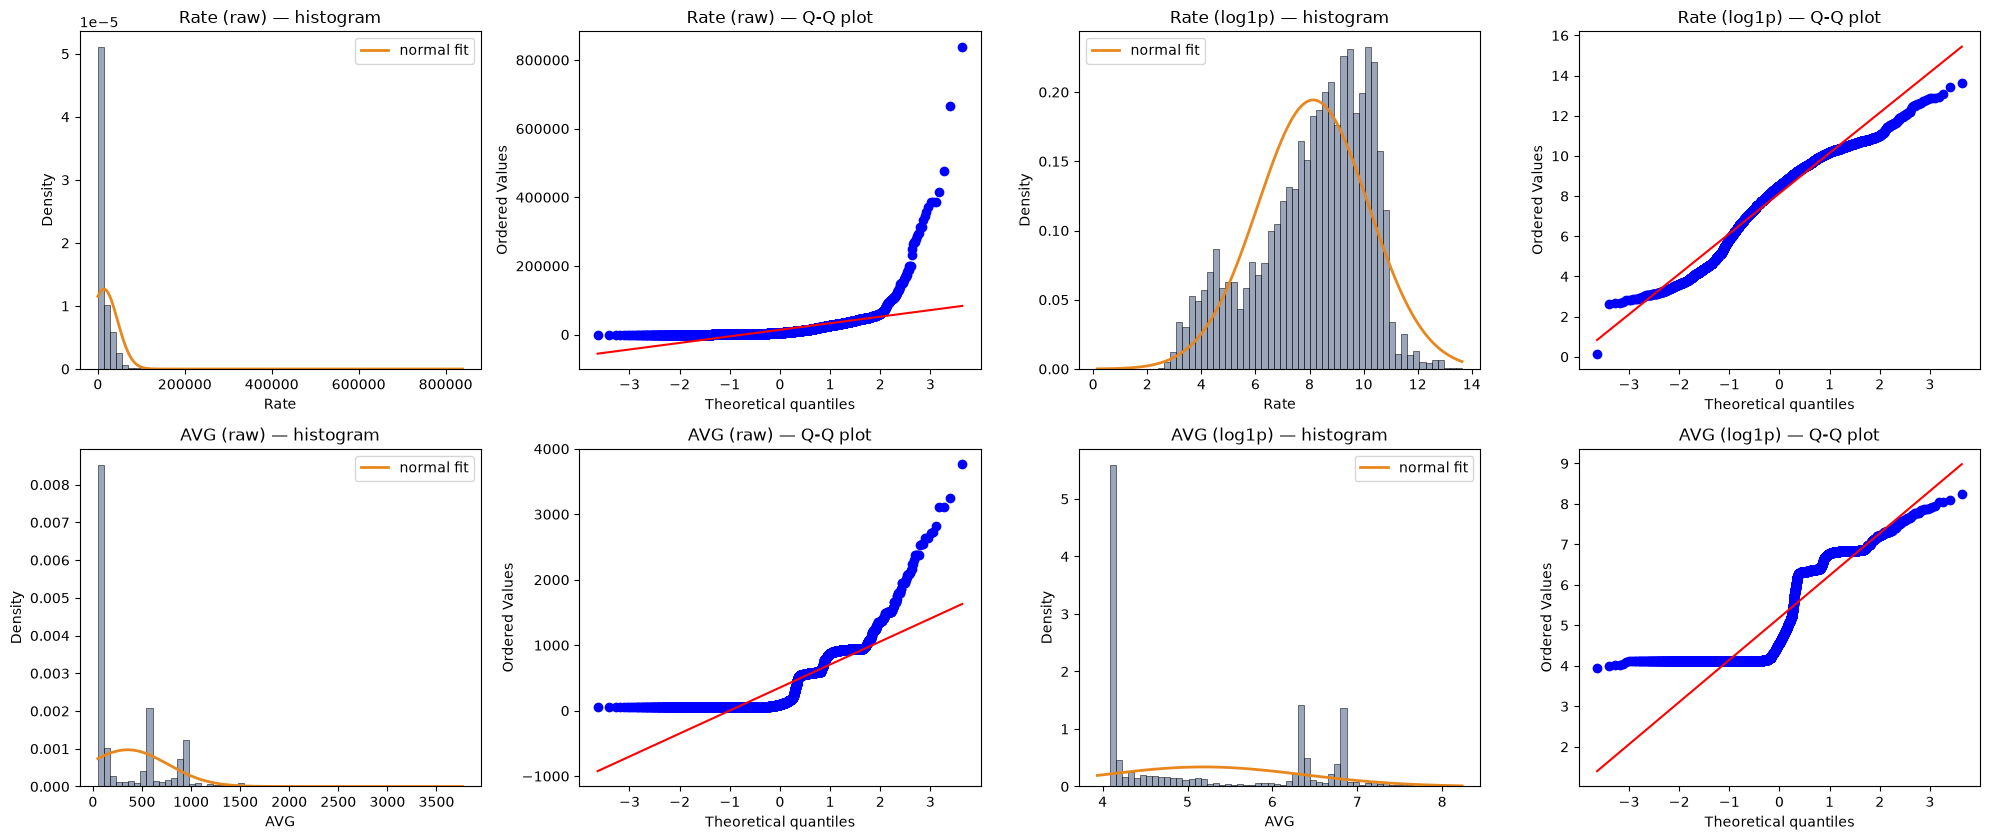

In [12]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8.5))
for j, c in enumerate(["Rate", "AVG"]):
    for k, (name, f) in enumerate([("raw", lambda v: v), ("log1p", np.log1p)]):
        x = f(df[c].astype("float64")).sample(5000, random_state=RANDOM_STATE)
        ax = axes[j, 2 * k]
        sns.histplot(x, bins=60, stat="density", ax=ax, color="#5B6B8C", alpha=.6)
        grid = np.linspace(x.min(), x.max(), 300)
        ax.plot(grid, stats.norm.pdf(grid, x.mean(), x.std()), color="#E8871E", lw=2, label="normal fit")
        ax.set_title(f"{c} ({name}) — histogram"); ax.legend()
        stats.probplot(x, dist="norm", plot=axes[j, 2 * k + 1]); axes[j, 2 * k + 1].set_title(f"{c} ({name}) — Q-Q plot")
plt.tight_layout(); savefig("normality_qq")

In [13]:
rows = []
for f in FAMILY_ORDER:
    g = df[df.attack_family == f]
    for c in NORM:
        for name, tf in [("raw", lambda v: v), ("log1p", np.log1p)]:
            r = norm_row(tf(g[c].astype("float64")))
            rows.append({"family": f, "variable": c, "scale": name, "Shapiro p": r["Shapiro p"], "skewness": r["skewness"]})
nf = pd.DataFrame(rows)
nf.to_csv(TABLE_DIR / "IoT23_eda_normality_by_family.csv", index=False)
pv = nf.pivot_table(index=["family"], columns=["scale", "variable"], values="Shapiro p")
reject = (nf["Shapiro p"] < 0.05).groupby(nf["scale"]).mean().mul(100).round(1)
print("share of (family, variable) combinations where Shapiro-Wilk rejects normality at 5 %:", reject.to_dict())
pv["log1p"].map(lambda p: f"{p:.1e}" if pd.notna(p) else "constant")

share of (family, variable) combinations where Shapiro-Wilk rejects normality at 5 %: {'log1p': 100.0, 'raw': 100.0}


variable,AVG,Header_Length,IAT,Max,Rate,Std,Time_To_Live,Tot_sum
family,,,,,,,,
Benign,2.9e-49,3.1e-59,4.0e-58,1.2e-41,1.1e-44,5.6e-50,2.0e-39,3.2e-49
Credential attacks,1.2e-57,3.0e-51,2.5e-94,5.8e-44,2.6e-46,3.5e-36,2.6e-29,1.6e-57
Denial of service,4.3e-75,4.1e-65,1.5e-87,6.4e-66,7.8e-36,5.0e-64,5.9e-85,6.8e-75
Interception and spoofing,7.2e-42,1.7e-50,4.7e-74,8.9e-52,5.5e-33,8.3e-58,3.1e-43,9.0e-42
Malware and botnets,4.5e-86,2.8e-68,8.2e-90,3.0e-88,7.1e-40,2.1e-65,4.2e-84,5.4e-89
Reconnaissance,1.6e-59,1.9e-45,1.1e-60,1.1e-43,5.0e-54,2.0e-48,2.1e-35,2.3e-59
Web and injection,1.5e-57,2.1e-45,3.2e-94,4.2e-42,4.0e-56,1.1e-51,3.3e-21,1.9e-57


**Interpretation — conclusion for the team.**
* **Shape:** raw skewness ranges from 1.3 (`Tot_sum`) to 1,821 (`IAT`), with excess kurtosis up to 3.6 million; a normal distribution has 0 for both.
* **Visual:** the histograms do not follow the fitted normal curve and the Q–Q plots bend away from the diagonal at both ends, even after the log transform (`AVG` becomes bimodal rather than normal).
* **Formal tests:** Shapiro–Wilk (n = 5,000) and D'Agostino K² (n = 100,000) reject normality for **every variable, raw and log-transformed (all p < 10⁻²⁰)**, and also **inside every one of the 7 families (100 % of the 112 combinations)** — the non-normality is not just caused by mixing families.

**Decision:** the normality assumption of the t-test and ANOVA does not hold, in the whole data or within groups. The team therefore uses **non-parametric tests**: Mann–Whitney U (benign vs attack, SQ1), Kruskal–Wallis with Dunn post-hoc (across families, SQ1) and Kolmogorov–Smirnov (same attack across networks, SQ2). These tests compare ranks or whole distributions and make no normality assumption.

---
## 5 · Chi-square test of independence: protocol × attack family (task 4.5, SQ1)
**Question:** is the network protocol of a traffic window associated with its attack family?
* **H₀:** `Protocol_Type` and `attack_family` are independent. **H₁:** they are associated.
* **Why this test:** both variables are categorical, and the observations are counts of windows → χ² test of independence on a contingency table.
* **Assumptions:** independent observations (duplicates were removed in phase 3); expected count ≥ 5 in at least 80 % of cells and ≥ 1 in all cells (Cochran). Rare protocols are merged if needed.
* **Effect size:** with millions of rows any association is significant, so the strength is measured by **Cramér's V** (0 = no association, 1 = perfect); the **standardised residuals** show *which* combinations drive it (|r| > 2 ≈ more or fewer than expected).

In [14]:
proto = df["Protocol_Type"].map(PROTO_NAMES)
ct0 = pd.crosstab(proto, df["attack_family"])[FAMILY_ORDER]
print("raw contingency table:"); display(ct0)
small = ct0.sum(axis=1) < 1000
proto_m = proto.where(~proto.isin(ct0.index[small]), "Other (non-IP)")      # merge very rare protocols (e.g. IGMP) into 'Other'
ct = pd.crosstab(proto_m, df["attack_family"])[FAMILY_ORDER]
chi2, p, dof, exp = stats.chi2_contingency(ct)
n = ct.values.sum(); r, k = ct.shape
V = np.sqrt(chi2 / (n * (min(r, k) - 1)))
phi2c = max(0, chi2 / n - (k - 1) * (r - 1) / (n - 1)); rc, kc = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
V_bc = np.sqrt(phi2c / min(kc - 1, rc - 1))                                     # bias-corrected Cramér's V
chi_res = pd.Series({"rows (n)": n, "table": f"{r} protocols x {k} families", "chi2": chi2, "dof": dof, "p-value": p,
                     "Cramér's V": V, "Cramér's V (bias-corrected)": V_bc,
                     "cells with expected < 5": f"{(exp < 5).mean() * 100:.1f} %", "min expected count": exp.min()})
print("merged into 'Other':", list(ct0.index[small]))
chi_res.to_frame("chi-square test")

raw contingency table:


attack_family,Benign,Denial of service,Malware and botnets,Reconnaissance,Interception and spoofing,Web and injection,Credential attacks
Protocol_Type,,,,,,,
GRE,0,0,396306,0,0,0,0
ICMP,53,396130,170,298,246,69,18
IGMP,0,0,0,1,2,0,0
Other (non-IP),428,346,98,4886,2876,306,133
TCP,182792,1722521,3149,423495,246295,17917,10429
UDP,16727,599440,200277,70450,117501,5415,1940


merged into 'Other': ['IGMP']


,chi-square test
rows (n),4420714
table,5 protocols x 7 families
chi2,3331689.123229
dof,24
p-value,0.0
Cramér's V,0.434066
Cramér's V (bias-corrected),0.434065
cells with expected < 5,0.0 %
min expected count,25.704336


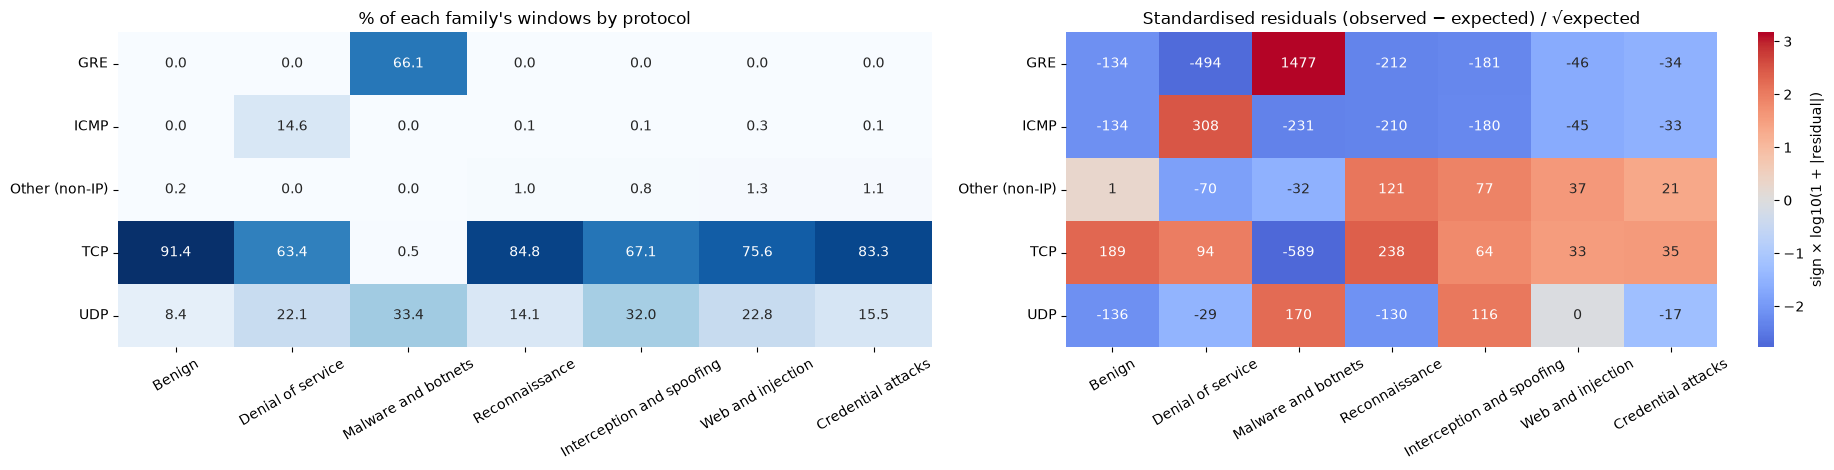

In [15]:
resid = (ct - exp) / np.sqrt(exp)
row_pct = (100 * ct / ct.sum(axis=0)).round(1)                                   # % of each family's windows using each protocol
fig, axes = plt.subplots(1, 2, figsize=(19, 4.8))
sns.heatmap(row_pct, annot=True, fmt=".1f", cmap="Blues", ax=axes[0], cbar=False); axes[0].set_title("% of each family's windows by protocol")
sns.heatmap(np.sign(resid) * np.log10(1 + resid.abs()), annot=resid.round(0).astype(int), fmt="d", cmap="coolwarm", center=0, ax=axes[1],
            cbar_kws={"label": "sign × log10(1 + |residual|)"})
axes[1].set_title("Standardised residuals (observed − expected) / √expected")
for a in axes: a.set_xlabel(""); a.set_ylabel(""); a.tick_params(axis="x", rotation=30); a.tick_params(axis="y", rotation=0)
plt.tight_layout(); savefig("chi_square_protocol_family")
resid.round(0).to_csv(TABLE_DIR / "IoT23_eda_chi2_residuals.csv"); row_pct.to_csv(TABLE_DIR / "IoT23_eda_protocol_by_family.csv")

**Robustness check.** The sample caps every label at 200,000 rows, so families with many labels (Denial of service: 16) weigh more. The test is repeated on a
**balanced** sample of 2,000 windows per family: if the association is real, it must still be clear with a small, equal-sized sample.

In [16]:
bal = per_group(df, "attack_family", 2000)
ctb = pd.crosstab(bal["Protocol_Type"].map(PROTO_NAMES).where(lambda s: ~s.isin(ct0.index[small]), "Other (non-IP)"), bal["attack_family"])
ctb = ctb.loc[ctb.sum(axis=1) > 0]
chi2b, pb, dofb, expb = stats.chi2_contingency(ctb)
Vb = np.sqrt(chi2b / (ctb.values.sum() * (min(ctb.shape) - 1)))
pd.Series({"rows": int(ctb.values.sum()), "chi2": chi2b, "dof": dofb, "p-value": pb, "Cramér's V": Vb,
           "cells with expected < 5": f"{(expb < 5).mean() * 100:.1f} %"}).to_frame("balanced sample")

,balanced sample
rows,14000
chi2,11968.189687
dof,24
p-value,0.0
Cramér's V,0.462296
cells with expected < 5,0.0 %


**Interpretation.**
* **Assumptions met:** all expected counts ≥ 25.7 (0 % of cells below 5) after merging the 3 IGMP windows into *Other*; windows are independent after the duplicate removal of phase 3.
* **Result:** χ²(24) = 3,331,689, p < 0.001 → **reject H₀**: the protocol of a window is associated with its attack family.
* **Strength:** Cramér's V = **0.43** (bias-corrected 0.43) — a **strong** association for a 5 × 7 table (V > 0.25 is usually considered strong for this many degrees of freedom). The balanced sample (2,000 windows per family, n = 14,000) gives the same conclusion (χ²(24) = 11,968, p < 0.001, V = **0.46**), so the result is not an artefact of the sample size or of the 200k cap.
* **Where it comes from** (standardised residuals):
  * **GRE → Malware and botnets** (residual +1,477): GRE appears *only* in Mirai windows (66 % of them); every other family has 0 GRE.
  * **ICMP → Denial of service** (+308): 14.6 % of DoS windows are ICMP (ICMP floods and fragmentation); almost no other family uses ICMP.
  * **UDP → Mirai (+170) and spoofing (+116)**: Mirai UDP-Plain and DNS spoofing.
  * **TCP → Benign (+189) and reconnaissance (+238)**, while Mirai uses almost no TCP (−589).
  * **Other / non-IP (ARP) → reconnaissance (+121) and spoofing (+77)**: ARP spoofing and host discovery.

**Answer to SQ1 (protocol):** the protocol alone already points strongly to some families (GRE ⇒ Mirai, ICMP ⇒ DoS) but not to others: benign, reconnaissance, web and credential attacks are all mostly TCP, so they must be told apart by other features.

---
## 6 · Interesting patterns and trends (task 4.4)
### 6.1 Every attack has a TCP-flag and protocol "fingerprint"
Mean share of packets with each flag / protocol, per attack label.

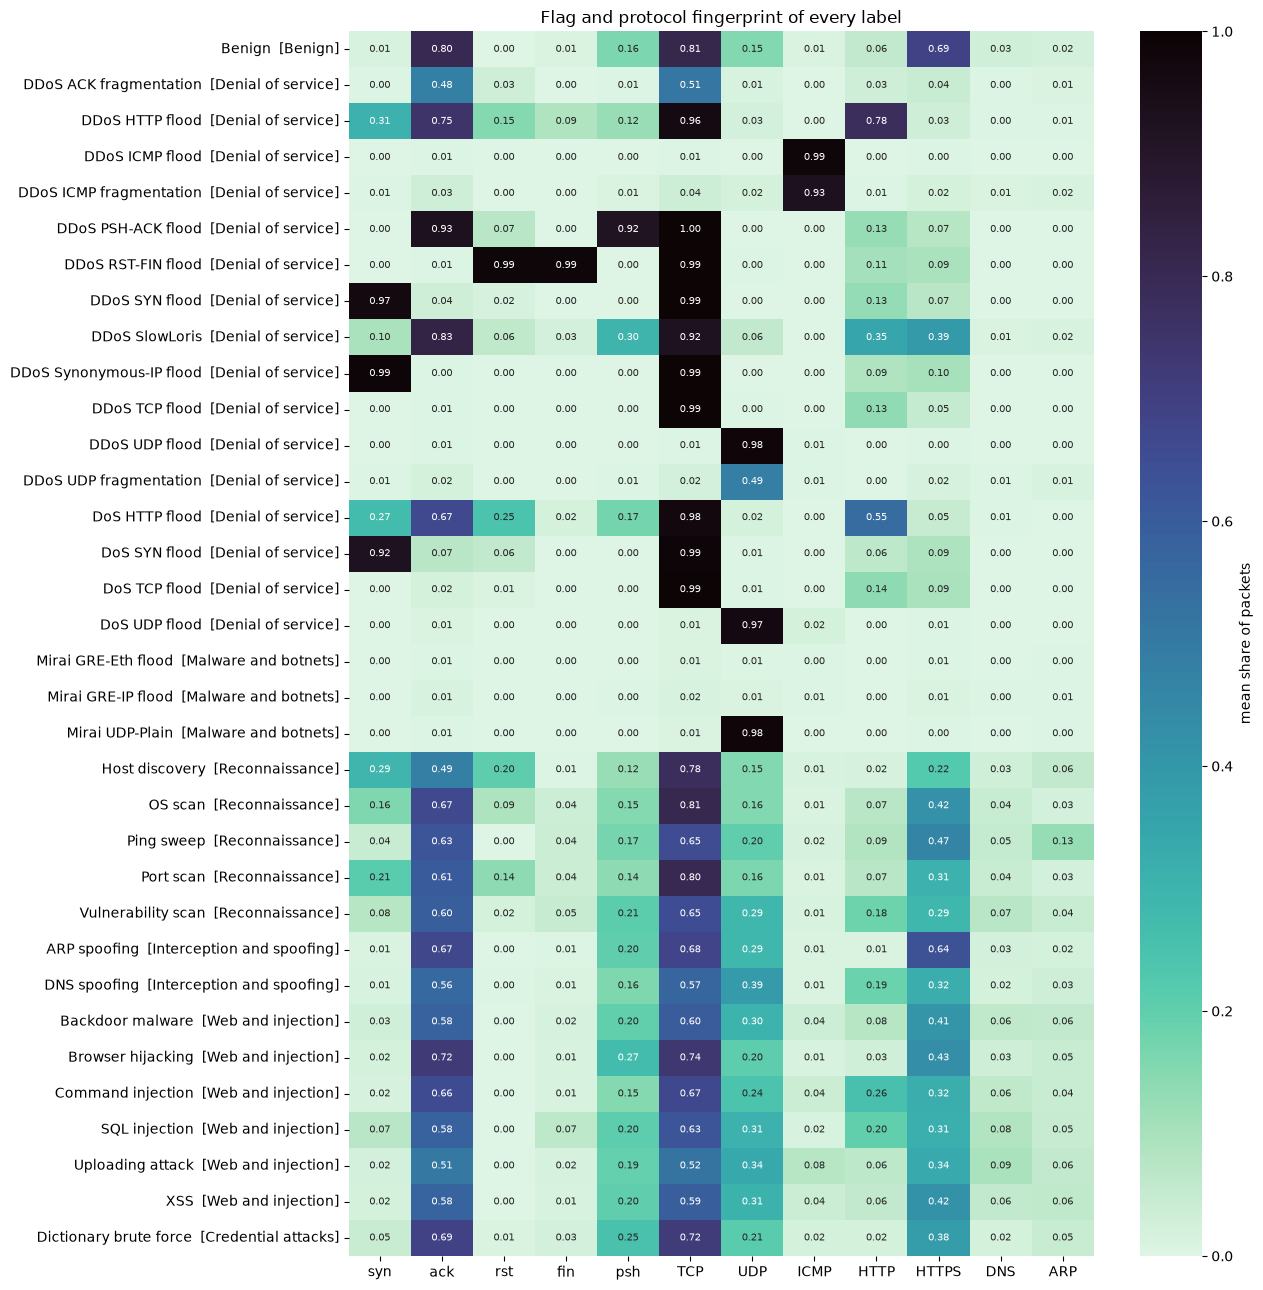

In [17]:
FP = ["syn_flag_number", "ack_flag_number", "rst_flag_number", "fin_flag_number", "psh_flag_number",
      "TCP", "UDP", "ICMP", "HTTP", "HTTPS", "DNS", "ARP"]
lab_fam = df.groupby("attack_label")["attack_family"].first()
order = lab_fam.map({f: i for i, f in enumerate(FAMILY_ORDER)}).sort_values(kind="stable").index
fpm = df.groupby("attack_label")[FP].mean().loc[order]
fpm.index = [f"{l}  [{lab_fam[l]}]" for l in fpm.index]
fig, ax = plt.subplots(figsize=(13, 13))
sns.heatmap(fpm.rename(columns=lambda c: c.replace("_flag_number", "")), annot=True, fmt=".2f", cmap="mako_r", vmin=0, vmax=1, ax=ax,
            annot_kws={"size": 7}, cbar_kws={"label": "mean share of packets"})
ax.set_title("Flag and protocol fingerprint of every label"); ax.set_ylabel("")
plt.tight_layout(); savefig("flag_fingerprints")

**Interpretation.** The floods have **unmistakable fingerprints**: SYN and Synonymous-IP floods ≈ 100 % SYN; PSH-ACK flood ≈ 93 % PSH and ACK; RST-FIN flood ≈ 99 % RST and FIN; ICMP floods ≈ 99 % ICMP; UDP floods and Mirai UDP-Plain ≈ 98 % UDP; the Mirai GRE floods are ≈ 0 on every TCP/UDP/ICMP column (they are GRE). HTTP floods stand out by their HTTP share (55–78 %).

The **low-volume attacks** (reconnaissance, web, credential, spoofing) all look like benign traffic: about 60–80 % TCP, ACK share 0.5–0.8 and 30–60 % HTTPS. Even *Ping sweep* is only 2 % ICMP. With windows of 10 packets, the few attack packets are mixed with the device's normal traffic, so the window describes the background more than the attack. This explains the overlap seen in §1 and is the main difficulty for SQ1 and SQ3.

### 6.2 Are DoS and DDoS distinguishable?
For each flood type present in both versions, compare the DoS (one attacker) and DDoS (many attackers) windows: medians, the Kolmogorov–Smirnov
distance between their distributions (0 = identical, 1 = completely separated), and the share of windows whose exact features also occur under the other label.

In [18]:
pairs_dd = [("DoS UDP flood", "DDoS UDP flood"), ("DoS TCP flood", "DDoS TCP flood"), ("DoS SYN flood", "DDoS SYN flood"), ("DoS HTTP flood", "DDoS HTTP flood")]
VARS = ["Rate", "IAT", "AVG", "Std", "Header_Length", "Time_To_Live", "Tot_sum"]
rows = []
for a, b in pairs_dd:
    A, B = df[df.attack_label == a], df[df.attack_label == b]
    if A.empty or B.empty: continue
    row = {"pair": f"{a} vs {b}", "conflicting rows %": round(100 * pd.concat([A, B])["conflicting_features"].mean(), 1)}
    for v in VARS:
        row[f"{v} median (DoS / DDoS)"] = f"{A[v].median():.3g} / {B[v].median():.3g}"
        row[f"KS {v}"] = stats.ks_2samp(A[v], B[v]).statistic
    rows.append(row)
dd = pd.DataFrame(rows).set_index("pair")
dd.to_csv(TABLE_DIR / "IoT23_eda_dos_vs_ddos.csv")
ks_cols = [c for c in dd.columns if c.startswith("KS")]
display(dd[["conflicting rows %"] + ks_cols].round(3))
dd[[c for c in dd.columns if "median" in c]]

,conflicting rows %,KS Rate,KS IAT,KS AVG,KS Std,KS Header_Length,KS Time_To_Live,KS Tot_sum
pair,,,,,,,,
DoS UDP flood vs DDoS UDP flood,8.4,0.198,0.194,0.332,0.206,0.091,0.154,0.332
DoS TCP flood vs DDoS TCP flood,14.1,0.138,0.137,0.039,0.059,0.040,0.057,0.039
DoS SYN flood vs DDoS SYN flood,14.6,0.099,0.095,0.028,0.033,0.105,0.057,0.028
DoS HTTP flood vs DDoS HTTP flood,0.0,0.332,0.333,0.400,0.420,0.246,0.065,0.399


,Rate median (DoS / DDoS),IAT median (DoS / DDoS),AVG median (DoS / DDoS),Std median (DoS / DDoS),Header_Length median (DoS / DDoS),Time_To_Live median (DoS / DDoS),Tot_sum median (DoS / DDoS)
pair,,,,,,,
DoS UDP flood vs DDoS UDP flood,1.4e+04 / 1.99e+04,7.3e-05 / 5.18e-05,61 / 60.1,2.56 / 1,8 / 8,64 / 64,6.1e+03 / 6.01e+03
DoS TCP flood vs DDoS TCP flood,1.66e+04 / 2e+04,6.22e-05 / 5.16e-05,60.1 / 60.1,0.6 / 0,20 / 20,64 / 64,6.01e+03 / 6.01e+03
DoS SYN flood vs DDoS SYN flood,1.72e+04 / 1.8e+04,5.94e-05 / 5.69e-05,60 / 60,0 / 0,20 / 20,64 / 64,6e+03 / 6e+03
DoS HTTP flood vs DDoS HTTP flood,1.83e+03 / 811,0.000554 / 0.00125,428 / 128,684 / 167,31.6 / 33.6,64.2 / 64.8,4.25e+04 / 1.28e+04


**Interpretation.** For the **TCP and SYN floods**, DoS and DDoS are practically identical: equal medians for packet size (60 B), header length (20 B), TTL (64) and bytes per window, and Kolmogorov–Smirnov distances of only **0.03–0.14** (0 = identical distributions). The only systematic difference is a slightly higher rate with many attackers (e.g. TCP flood 16,600 vs 20,000 pkt/s). 14–15 % of these windows have *exactly* the same features as a window of the other label. The **UDP flood** pair differs a little more (KS up to 0.33 on packet size), and the **HTTP floods** are clearly different (KS 0.25–0.42 on rate, packet size and header length; DoS HTTP flood uses larger packets and a higher rate, and no window is shared).

**Conclusion:** at window level the number of attackers is mostly invisible — a detector can recognise *a TCP/SYN/UDP flood*, but should not be expected to tell DoS from DDoS. This supports analysing and modelling at the **family level** (shared taxonomy) rather than the 34 labels, and confirms the decision to flag `conflicting_features` (pending team agreement).

### 6.3 Which features separate the families best?

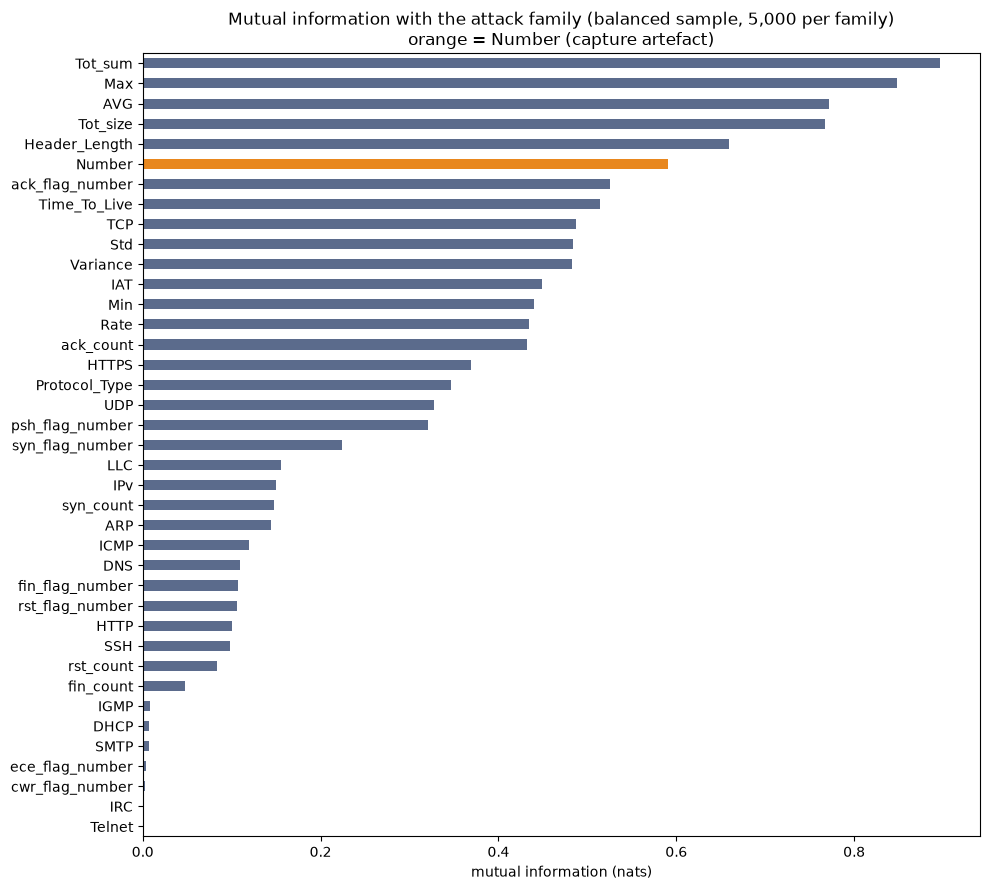

,MI with attack_family,MI with is_attack
Tot_sum,0.897,0.094
Max,0.848,0.106
AVG,0.772,0.087
Tot_size,0.768,0.086
Header_Length,0.660,0.079
Number,0.590,0.054
ack_flag_number,0.526,0.072
Time_To_Live,0.515,0.083
TCP,0.487,0.053
Std,0.484,0.073


In [19]:
B = per_group(df, "attack_family", 5000)
X = B[FEATURES].astype("float64")
disc = [c == "Protocol_Type" for c in FEATURES]
mi_fam = mutual_info_classif(X, B["attack_family"], discrete_features=disc, random_state=RANDOM_STATE)
mi_att = mutual_info_classif(X, B["is_attack"], discrete_features=disc, random_state=RANDOM_STATE)
mi = pd.DataFrame({"MI with attack_family": mi_fam, "MI with is_attack": mi_att}, index=FEATURES).sort_values("MI with attack_family", ascending=False)
mi.to_csv(TABLE_DIR / "IoT23_eda_mutual_information.csv")
fig, ax = plt.subplots(figsize=(10, 9))
mi["MI with attack_family"][::-1].plot.barh(ax=ax, color=["#E8871E" if c == "Number" else "#5B6B8C" for c in mi.index[::-1]])
ax.set_title("Mutual information with the attack family (balanced sample, 5,000 per family)\norange = Number (capture artefact)"); ax.set_xlabel("mutual information (nats)")
plt.tight_layout(); savefig("mutual_information")
mi.head(15).round(3)

In [20]:
art = df.groupby("attack_family")["Number"].agg(**{"% windows with < 100 packets": lambda s: 100 * (s < 100).mean(), "median packets": "median"}).loc[FAMILY_ORDER]
art.round(1)

,% windows with < 100 packets,median packets
attack_family,,
Benign,100.0,10.0
Denial of service,0.4,100.0
Malware and botnets,0.6,100.0
Reconnaissance,100.0,10.0
Interception and spoofing,100.0,10.0
Web and injection,100.0,10.0
Credential attacks,100.0,10.0


**Interpretation.** The features that separate the families best are the **packet-size** features (`Tot_sum`, `Max`, `AVG`) and `Header_Length`, followed by `Number`, the ACK share and `Time_To_Live`. Two warnings for feature selection (phase 5):
* **`Number` is a construction artefact.** Every benign, reconnaissance, spoofing, web and credential window has fewer than 100 packets (median **10**), while 99.4–99.6 % of DoS and Mirai windows have exactly 100. The dataset was clearly cut into 10-packet windows for some captures and 100-packet windows for the floods. `Number` — and `Tot_sum`, which is `AVG` × `Number` and tops the ranking partly for that reason — would let a model recognise the *capture setting* instead of the attack. They should be removed (or used only to show the effect).
* **`Time_To_Live`** ranks high partly because the attack machines share one OS (§1.2): it is a lab-specific signal that will not transfer to other networks (SQ2).

Mutual information with `is_attack` alone is much lower (≤ 0.11) than with the family (up to 0.90): it is far easier to tell *which* flood a window belongs to than to separate the quiet attacks from benign traffic.

---
## 7 · Comparison with the NetFlow datasets at family level (task 4.7, SQ2)
CICIoT2023 cannot be merged with NetFlow (different unit and features, see notebook 05), so the comparison is made **per attack family** on three concepts
that both representations measure:

| Concept | CICIoT2023 (window) | NetFlow v3 (flow) |
|---|---|---|
| Mean packet size (bytes) | `AVG` | (`IN_BYTES` + `OUT_BYTES`) / (`IN_PKTS` + `OUT_PKTS`) |
| Packet rate (packets/s) | `Rate` | (`IN_PKTS` + `OUT_PKTS`) / (`FLOW_DURATION_MILLISECONDS` / 1000), flows of 0 ms excluded |
| Protocol mix (% TCP / UDP / ICMP) | `Protocol_Type` | `PROTOCOL` |

The cell below reads the teammates' cleaned NetFlow files when they exist in `data/processed/` (`netflow_merged.parquet`, or `UNSW/CIC18/ToN/BoT_clean.parquet`).

In [21]:
def concepts_iot(d):
    g = d.groupby("attack_family")
    return pd.DataFrame({"median packet size (B)": g["AVG"].median(), "median rate (pkt/s)": g["Rate"].median(),
                         "% TCP": g["Protocol_Type"].apply(lambda s: 100 * (s == 6).mean()),
                         "% UDP": g["Protocol_Type"].apply(lambda s: 100 * (s == 17).mean()),
                         "% ICMP": g["Protocol_Type"].apply(lambda s: 100 * (s == 1).mean())})

def concepts_netflow(d):
    pk = d["IN_PKTS"] + d["OUT_PKTS"]; by = d["IN_BYTES"] + d["OUT_BYTES"]; dur = d["FLOW_DURATION_MILLISECONDS"] / 1000
    t = pd.DataFrame({"fam": d["attack_family"].astype(str), "size": by / pk.replace(0, np.nan),
                      "rate": (pk / dur).where(dur > 0), "proto": d["PROTOCOL"]})
    g = t.groupby("fam")
    return pd.DataFrame({"median packet size (B)": g["size"].median(), "median rate (pkt/s)": g["rate"].median(),
                         "% TCP": g["proto"].apply(lambda s: 100 * (s == 6).mean()), "% UDP": g["proto"].apply(lambda s: 100 * (s == 17).mean()),
                         "% ICMP": g["proto"].apply(lambda s: 100 * (s == 1).mean())})

cmp = {"IoT23": concepts_iot(df)}
nf_files = [PROCESSED_DIR / "netflow_merged.parquet"] if (PROCESSED_DIR / "netflow_merged.parquet").exists() else \
           [PROCESSED_DIR / f"{k}_clean.parquet" for k in ("UNSW", "CIC18", "ToN", "BoT") if (PROCESSED_DIR / f"{k}_clean.parquet").exists()]
cols = ["IN_PKTS", "OUT_PKTS", "IN_BYTES", "OUT_BYTES", "FLOW_DURATION_MILLISECONDS", "PROTOCOL", "attack_family", "source_dataset"]
for f in nf_files:
    nfd = pd.read_parquet(f, columns=cols)
    for src, part in nfd.groupby("source_dataset", observed=True):
        cmp[str(src)] = concepts_netflow(part)
print("NetFlow files found:", [f.name for f in nf_files] or "none yet — only CICIoT2023 is shown; re-run this cell once the teammates' cleaned files are in data/processed/")
comparison = pd.concat(cmp, names=["source", "attack_family"]).round(2)
comparison.to_csv(TABLE_DIR / "IoT23_eda_netflow_comparison.csv")
comparison

NetFlow files found: none yet — only CICIoT2023 is shown; re-run this cell once the teammates' cleaned files are in data/processed/


median packet size (B)  median rate (pkt/s)  % TCP  % UDP  % ICMP
source attack_family                                                                               
IoT23  Benign                                 249.800003           170.600006  91.40   8.36    0.03
       Credential attacks                     120.500000           106.629997  83.30  15.50    0.14
       Denial of service                       60.290001         12291.000000  63.36  22.05   14.57
       Interception and spoofing              359.299988           482.369995  67.12  32.02    0.07
       Malware and botnets                    572.799988          4402.589844   0.52  33.38    0.03
       Reconnaissance                         106.599998           122.010002  84.85  14.11    0.06
       Web and injection                      144.199997            72.510002  75.58  22.84    0.29

**Interpretation (CICIoT2023 side).** Per family, CICIoT2023 shows: DoS = small packets (60 B) at a very high rate with 15 % ICMP; Mirai = large packets (573 B), high rate, GRE/UDP; benign = mid-size packets (250 B), low rate, 91 % TCP; reconnaissance, web and credential attacks = small-to-mid packets at low rates, 75–85 % TCP. The NetFlow side of this table fills in automatically when the teammates' cleaned files are placed in `data/processed/`; the question for SQ2 is then whether, e.g., DoS has the smallest packets and the highest rate *in every network*. Values are compared on their **rank order across families**, not on their absolute size: a window rate and a flow rate are not the same measurement.

---
## 8 · Summary of the CICIoT2023 EDA

| Question | Answer from the CICIoT2023 data |
|---|---|
| Are the features normally distributed? | **No** — not raw, not after log, not within any family (all Shapiro–Wilk p < 10⁻²⁰). → The team uses non-parametric tests. |
| Is protocol associated with the attack family? (SQ1) | **Yes, strongly**: χ²(24) = 3.33 M, p < 0.001, Cramér's V = 0.43 (0.46 on a balanced sample). GRE ⇒ Mirai, ICMP ⇒ DoS, non-IP ⇒ reconnaissance / spoofing. |
| What distinguishes attacks from benign traffic? (SQ1) | Floods: very high rate, minimum-size or uniform packets, a single dominant flag or protocol. Benign: low rate, large and variable packets, HTTPS. |
| Which attacks are hard to detect? | Reconnaissance, web, credential and spoofing windows look like benign traffic (similar rate, size, flags, protocol mix). |
| Can DoS and DDoS be told apart? | Not for TCP/SYN floods (KS ≤ 0.14, 14–15 % identical windows); partly for UDP; yes for HTTP floods. → Analyse at family level. |
| Which features are redundant? | 12 pairs with \|ρ\| ≥ 0.9: `Tot_size`/`AVG`, `LLC`/`IPv`/`ARP`, `Variance`/`Std`, `*_count`/`*_flag_number`, `Rate`/`IAT`. |
| Which features are artefacts? | `Number` (10-packet vs 100-packet windows by capture), `Tot_sum` (contains `Number`), `Time_To_Live` (attack-machine OS). |

**Hand-over to feature engineering (phase 5):** log-transform the skewed features; keep one feature per redundant group; drop or isolate `Number`, `Tot_sum` and `Time_To_Live`; one-hot encode `Protocol_Type`; use robust scaling fitted on the training set only.